# Week 5 - Transfer Learning
Project 2: Neural Networks, Convolutions, and Transfer Learning (Intel Image Classification, ResNet-18)

**Before running:** Settings -> Accelerator = GPU T4, Internet = On. Add dataset *Intel Image Classification* (puneet6060).

In [2]:
!ls /kaggle/input/datasets/puneet6060
!ls /kaggle/input/datasets/puneet6060/*

intel-image-classification
seg_pred  seg_test  seg_train


## Part 1: The Data, and an Image as Numbers

In [3]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


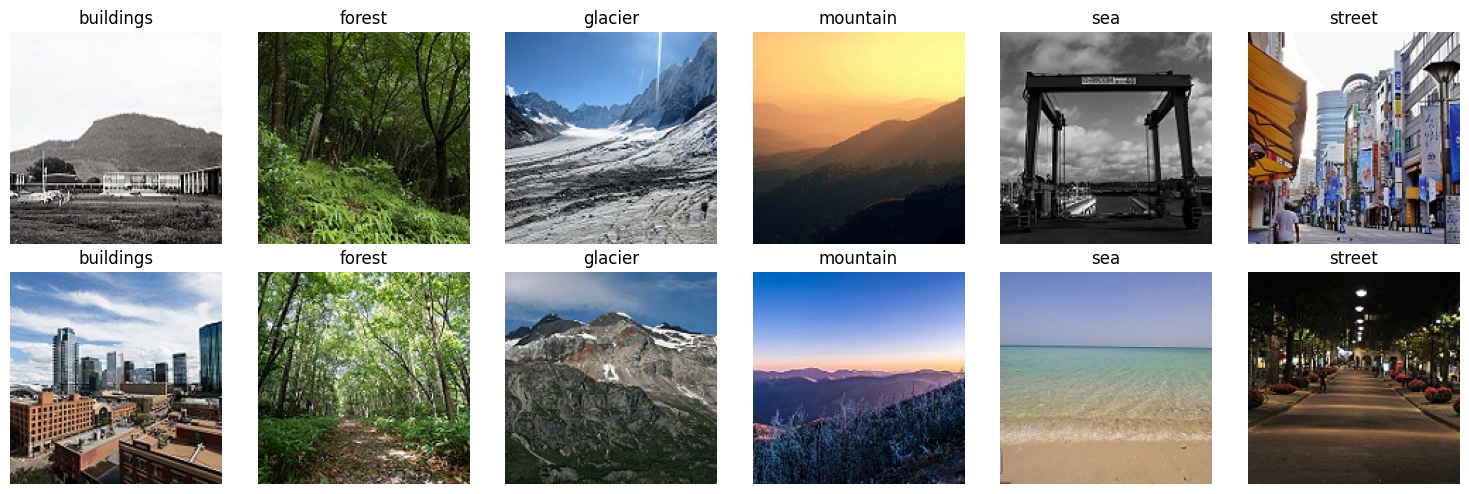

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### Write it (Part 1)

**Prediction:** Before running Part 6, I expected buildings and glacier to be the most confused pair, because both have large pale or grey areas (walls, concrete, ice) in the sample grid. I did not write this prediction down at the time.

**Image facts:** The image has shape (150, 150, 3): 150 pixels high, 150 wide, and 3 colour channels (R, G, B). The data type is uint8 and the pixel values range from 0 to 255.

## Part 2: Convolution and Parameters by Hand

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


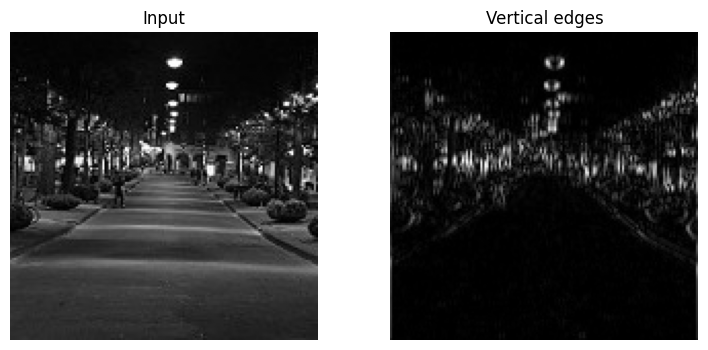

In [5]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

In [6]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64 : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')    # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64 : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### Write it (Part 2)

**Conv parameters:** (K x K x C_in + 1) x C_out = (3 x 3 x 3 + 1) x 64 = 28 x 64 = **1,792**

**Dense parameters:** 150 x 150 x 3 = 67,500 inputs. 67,500 x 512 weights + 512 biases = 34,560,000 + 512 = **34,560,512**

**Ratio:** 34,560,512 / 1,792 = **19,286 times more** parameters for the dense layer.

**Weight sharing:** A conv layer reuses the same small filter at every position, so a pattern learned in one corner is automatically detected anywhere else in the image. A dense layer would have to learn the same object separately for each location.

## Part 3: Transforms and Data Loaders

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


### Write it (Part 3)

**Split sizes:** 11,929 training images, 2,105 validation images (15% of the 14,034 training images), and 3,000 test images.

**Wrong augmentation for this dataset:** RandomRotation(90) (or a vertical flip). A sea or a glacier turned upside down is no longer a realistic scene, so the model would learn from images it will never see in real photos.

**Wrong augmentation for handwritten digits:** A horizontal flip or a 180-degree rotation. A flipped or rotated 6 can look like a 9, and a flipped 2 or 5 is not a valid digit, so labels would become wrong.

## Part 4: Training Loop and Feature Extraction

In [8]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                         # forward pass
            loss = F.cross_entropy(logits, yb)         # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                        # backpropagation
                optimizer.step()                       # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

In [9]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                            # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))   # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (69s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (35s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (34s)
Best validation accuracy, feature extraction: 0.901


### Write it (Part 4)

**Validation accuracy per epoch:** epoch 1 = 0.894, epoch 2 = 0.899, epoch 3 = 0.901. Best = 0.901. Trainable parameters: 3,078 out of 11,179,590.

**Why high accuracy with only 3,078 trainable parameters (0.03%)?** ResNet-18 was pretrained on 1.2 million ImageNet photos, so its early layers already detect edges, textures and object parts that are useful for almost any photo (slide 20). Only the last linear layer (512 x 6 weights + 6 biases) has to learn to map these existing features to our 6 scene classes.

## Part 5: Fine-Tuning and Learning Curves

In [10]:
for p in model.layer4.parameters():
    p.requires_grad = True                       # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.227 acc 0.924 (35s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.931 (36s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.219 acc 0.926 (36s)
Best validation accuracy, fine-tuned: 0.931


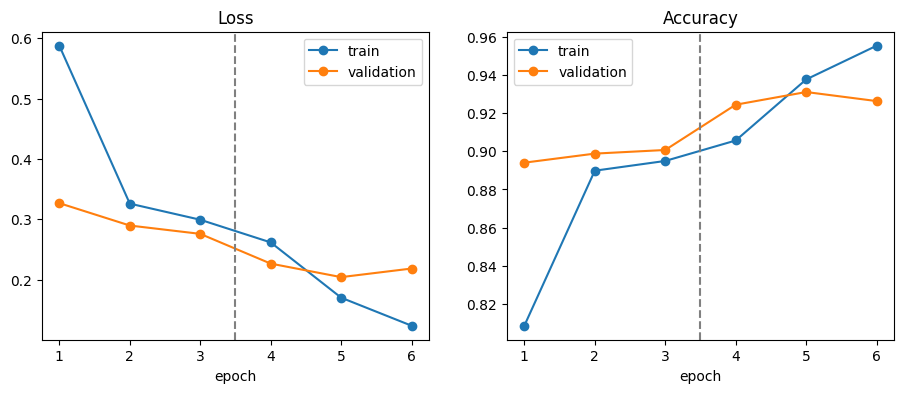

In [11]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')        # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

### Write it (Part 5)

**Improvement:** Best validation accuracy was 0.901 with feature extraction and 0.931 after fine-tuning layer4, an improvement of 3.0 points.

**What the curves show:** In epochs 1-3 (feature extraction) both losses fall slowly: validation loss goes 0.327, 0.290, 0.276. When layer4 is unfrozen at epoch 4, validation accuracy jumps to 0.924 and reaches 0.931 at epoch 5. Training loss keeps falling to 0.124 at epoch 6.

**Overfitting?** There is a small sign. From epoch 5 to epoch 6 training loss falls (0.170 to 0.124) while validation loss rises (0.204 to 0.219), and validation accuracy drops from 0.931 to 0.926. Overfitting is just starting, so keeping the best validation epoch (epoch 5) was the right choice.

**Why train accuracy can be lower than validation accuracy:** Training images are augmented (random crop, flip, colour jitter) so they are harder, while validation images are clean. Training accuracy is also averaged during the epoch while the weights are still changing. For example, in epoch 1 training accuracy was 0.809 but validation accuracy was 0.894. From epoch 5 the model fits the training set better and training accuracy (0.938, 0.955) goes above validation accuracy.

## Part 6: Test Once, Then Study the Errors

Test accuracy: 0.936
              precision    recall  f1-score   support

   buildings      0.956     0.904     0.929       437
      forest      0.994     0.985     0.989       474
     glacier      0.923     0.870     0.896       553
    mountain      0.884     0.918     0.901       525
         sea      0.945     0.982     0.963       510
      street      0.925     0.962     0.943       501

    accuracy                          0.936      3000
   macro avg      0.938     0.937     0.937      3000
weighted avg      0.936     0.936     0.936      3000



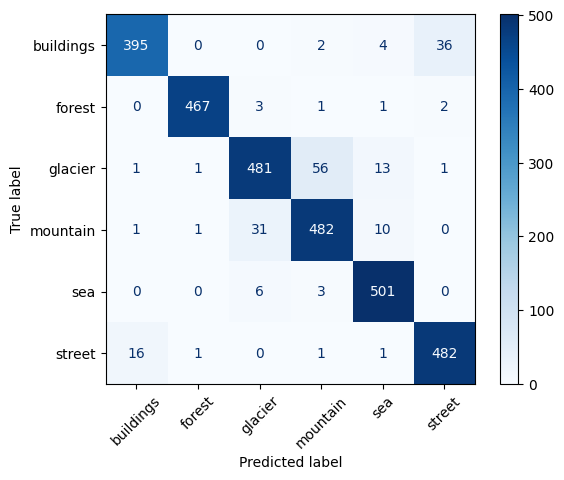

In [12]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

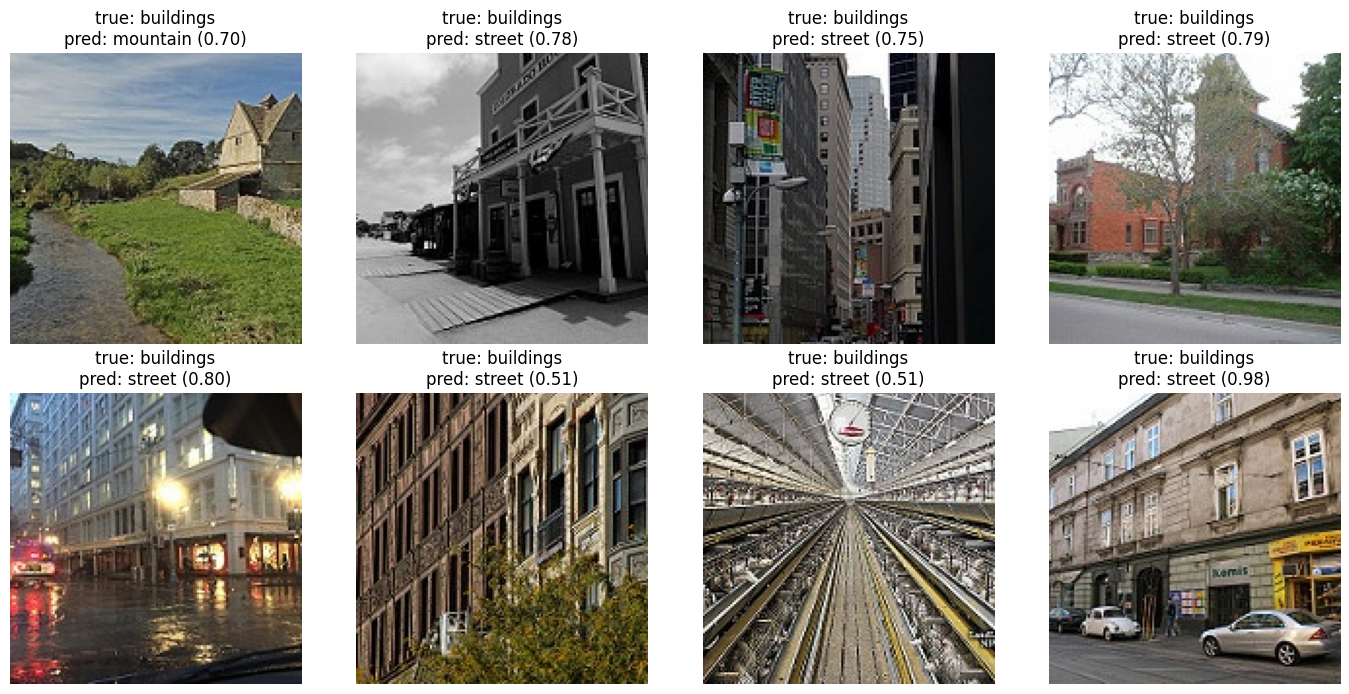

In [13]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

In [14]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   7.99   probability 1.000
forest     logit  -9.40   probability 0.000
glacier    logit  -4.61   probability 0.000
mountain   logit  -5.03   probability 0.000
sea        logit  -4.62   probability 0.000
street     logit  -3.53   probability 0.000


### Write it (Part 6)

**Test accuracy:** 0.936 (2,808 of 3,000 images correct).

**Two weakest classes by recall:** glacier (recall 0.870) and buildings (recall 0.904).

**Most confused pair:** glacier and mountain. 56 glacier images were predicted as mountain and 31 mountain images as glacier (87 errors in total). The second largest pair is buildings and street (36 and 16).

**Was my prediction right?** No. I expected buildings and glacier to be confused with each other, but there were almost no errors between them (0 and 1 images). Interestingly, they were the two classes with the lowest recall, but for different reasons: glacier was confused with mountain, and buildings with street. Both pairs have similar scene content (snowy peaks, and streets lined with buildings).

**Error gallery:**
1. true buildings, predicted mountain (0.70): the photo shows a small stone house surrounded by grass, a stream and trees. The image is ambiguous, because it looks more like a landscape than a building scene, and the model's confidence is low.
2. true buildings, predicted street (0.51): a view of long parallel rails and steel beams inside what looks like an industrial hall or station. This looks like a questionable label, because there is no clear building facade or street, and the model's low confidence (0.51) shows it was unsure too.

**Softmax on one image:** For the first test image (true class buildings) the logit for buildings was 7.99 and all others were negative (-3.53 to -9.40), giving probability 1.000 for buildings and 0.000 for the rest.

## Part 7: Save

In [15]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


### Write it (Part 7)

The model weights were saved as resnet18_intel.pt (44.8 MB), which is under GitHub's 100 MB limit. The README and LinkedIn post use the numbers from this notebook: validation accuracy 0.901 (feature extraction) and 0.931 (fine-tuned), test accuracy 0.936.

## Check Your Understanding

**1. Why does a network without nonlinear activations collapse to one linear layer?**
Without a nonlinear activation, each layer is only a matrix multiplication plus a bias. Stacking two of them gives W2(W1 x) = (W2 W1) x, which is just one new matrix. So any number of linear layers can only do what a single linear layer can do, and extra depth adds nothing.

**2. Logits [3, 1, 0]: what probability does softmax give the first class?**
e^3 = 20.09, e^1 = 2.718, e^0 = 1.
Sum = 20.09 + 2.718 + 1 = 23.81.
p(first class) = 20.09 / 23.81 = **0.844**

**3. How many parameters does a 3 x 3 convolution from 64 to 128 channels have?**
Parameters = (K x K x C_in + 1) x C_out = (3 x 3 x 64 + 1) x 128 = 577 x 128 = **73,856**

**4. An input of 56 x 56 goes through a 3 x 3 convolution with padding 1 and stride 2. What is the output size?**
Output = (W - K + 2P) / S + 1 = (56 - 3 + 2) / 2 + 1 = 55 / 2 + 1 = 27.5 + 1. Rounding the division down gives 27 + 1 = **28**, so the output is 28 x 28.

**5. Why does a residual (skip) connection help gradients reach the early layers?**
A residual block computes y = F(x) + x, so dy/dx = dF/dx + 1. The "+1" gives the gradient a direct path backwards through every block, so it does not shrink towards zero as it passes through many layers. This is why very deep networks such as ResNet can be trained.

**6. When would you train a CNN from scratch instead of using transfer learning?**
When I have a very large labelled dataset, or when my images are very different from everyday photos (for example radar images or spectrograms), so features learned on ImageNet would not help.